
# Graph Neural Networks from Scratch — Tutorial 1: Understanding Graphs and Their Representations

### From nodes and edges to learning on complex, connected systems

*📺 Video on YouTube | 🐍 Python · NumPy · PyTorch | Beginner–Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

Most deep learning tutorials begin with images, sequences, or tabular data. But what happens when the data is not arranged in a regular grid? What if the relationships between data points are just as important as the data itself?

That's where **Graph Neural Networks (GNNs)** come in.

In this tutorial series, we'll build our understanding of GNNs step by step — starting with the mathematical foundations of graphs, implementing graph convolution from scratch, and gradually moving towards modern GNN architectures and real-world scientific applications.

We'll focus not only on *how to use* GNN libraries, but also on understanding what's happening inside the network: how information travels between nodes, how neighbourhoods are aggregated, and how a graph structure becomes a learnable representation.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| **1** | **Graph Fundamentals and Representations** | **nodes, edges, adjacency matrices, graph features** | **📍 You are here** |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | trainable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | practical GNN implementation, real graph dataset | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | Next |
| 6 | Graph Attention Networks (GAT) | attention-based neighbourhood aggregation | Planned |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to move from understanding a simple graph to building models that can learn from complex connected systems — including computational meshes and physical systems.

> **New to deep learning?** You don't need prior experience with GNNs to follow this series. We'll build the graph concepts from the ground up and introduce the mathematics and code progressively. Basic Python, NumPy, and familiarity with neural networks will be helpful.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay particular attention to the later tutorials. Graphs provide a natural way to represent unstructured meshes, connectivity, and interactions between physical entities — making GNNs particularly interesting for engineering applications.

**Let's start by understanding the data structure that makes all of this possible: the graph.**


---

## 1 — Why do we need Graph Neural Networks?

Many machine-learning problems are naturally represented as a collection of independent data points:

- images → pixels arranged on a regular grid
- time series → observations arranged along time
- tabular data → rows and columns

But many real systems are about **relationships**.

Examples:

| Problem | Nodes | Edges |
|---|---|---|
| Social network | people | friendships |
| Molecule | atoms | chemical bonds |
| Road network | intersections | roads |
| Power grid | substations | transmission lines |
| CFD mesh | cells / vertices | neighbouring cells / vertices |
| Finite-element mesh | nodes | element connectivity |

For these problems, knowing the properties of an individual object is often not enough.

A node may need information from its **neighbours**.

That is the basic motivation for a GNN:

> **A GNN learns representations of nodes by combining information from the nodes around them.**



---

## 2 — What is a graph?

A graph can be written as

$$
G = (V, E)
$$

where:

- $V$ = set of **vertices (nodes)**
- $E$ = set of **edges (connections)**

Consider this small graph:

```text
          Alice
         /     \
        /       \
      Bob     Charlie
       |         |
       |         |
      David ---- Eve
```

We have five nodes:

$$
V = \{\text{Alice, Bob, Charlie, David, Eve}\}
$$

and five connections:

$$
E =
\{
(Alice,Bob),
(Alice,Charlie),
(Bob,David),
(Charlie,Eve),
(David,Eve)
\}
$$

Let's create this graph in Python.


In [24]:
# Our first graph

nodes = ["Alice", "Bob", "Charlie", "David", "Eve"]

edges = [
    ("Alice", "Bob"),
    ("Alice", "Charlie"),
    ("Bob", "David"),
    ("Charlie", "Eve"),
    ("David", "Eve"),
]

print("Nodes:")
print(nodes)

print("\nEdges:")
for edge in edges:
    print(edge)


Nodes:
['Alice', 'Bob', 'Charlie', 'David', 'Eve']

Edges:
('Alice', 'Bob')
('Alice', 'Charlie')
('Bob', 'David')
('Charlie', 'Eve')
('David', 'Eve')



### 🧪 Hands-on Exercise 1

Modify the graph above:

1. Add a new node called `Frank`.
2. Connect `Frank` to `Eve`.
3. Connect `Frank` to `Bob`.
4. Print the new node and edge lists.

**Do not look at the solution immediately.**

<details>
<summary>Hint</summary>

A node is just a string, and an edge is a tuple containing two node names.

</details>


In [17]:

# YOUR CODE HERE
# 1. Add Frank
# 2. Add (Eve, Frank)
# 3. Add (Bob, Frank)
# 4. Print the updated graph


In [22]:

# Solution

nodes = ["Alice", "Bob", "Charlie", "David", "Eve", "Frank"]

edges = [
    ("Alice", "Bob"),
    ("Alice", "Charlie"),
    ("Bob", "David"),
    ("Charlie", "Eve"),
    ("David", "Eve"),
    ("Eve", "Frank"),
    ("Bob", "Frank"),
]

print(nodes)
print(edges)


['Alice', 'Bob', 'Charlie', 'David', 'Eve', 'Frank']
[('Alice', 'Bob'), ('Alice', 'Charlie'), ('Bob', 'David'), ('Charlie', 'Eve'), ('David', 'Eve'), ('Eve', 'Frank'), ('Bob', 'Frank')]



---

## 3 — Visualising the graph

Before doing any mathematics, let's see the graph.

We will give every node a 2D position and draw the edges between them.


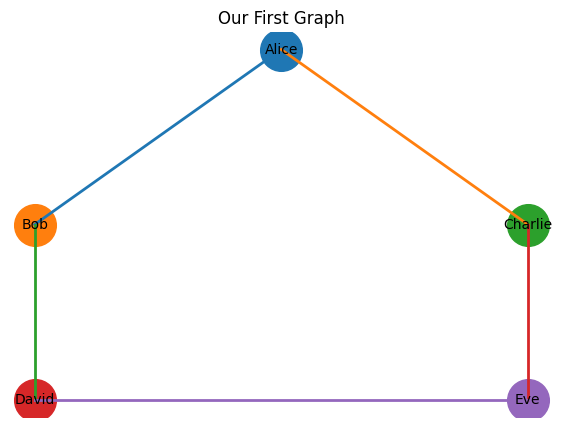

In [25]:

import matplotlib.pyplot as plt

positions = {
    "Alice":   (0, 1),
    "Bob":     (-1, 0),
    "Charlie": (1, 0),
    "David":   (-1, -1),
    "Eve":     (1, -1),
}

plt.figure(figsize=(7, 5))

# Draw edges
for a, b in edges:
    xa, ya = positions[a]
    xb, yb = positions[b]
    plt.plot([xa, xb], [ya, yb], linewidth=2)

# Draw nodes
for node, (x, y) in positions.items():
    plt.scatter(x, y, s=900)
    plt.text(x, y, node, ha="center", va="center", fontsize=10)

plt.title("Our First Graph")
plt.axis("off")
plt.show()



---

## 4 — From a graph to numbers

A neural network cannot directly work with the words `Alice`, `Bob`, etc.

We need a numerical representation.

One of the most important representations is the **adjacency matrix**.

For $N$ nodes, the adjacency matrix $A$ is an $N \times N$ matrix:

$$
A_{ij} =
\begin{cases}
1 & \text{if node } i \text{ is connected to node } j \\
0 & \text{otherwise}
\end{cases}
$$

For example, if Alice is connected to Bob:

$$
A_{\text{Alice},\text{Bob}} = 1
$$

If Alice is not connected to David:

$$
A_{\text{Alice},\text{David}} = 0
$$

For this tutorial, we use an **undirected graph**, so:

$$
A_{ij} = A_{ji}
$$


In [26]:

import numpy as np

# Use a fixed node ordering.
nodes = ["Alice", "Bob", "Charlie", "David", "Eve"]

node_to_id = {node: i for i, node in enumerate(nodes)}

A = np.zeros((len(nodes), len(nodes)), dtype=int)

for a, b in edges:
    i = node_to_id[a]
    j = node_to_id[b]
    A[i, j] = 1
    A[j, i] = 1  # undirected graph

print("Node-to-index mapping:")
print(node_to_id)

print("\nAdjacency matrix:")
print(A)


Node-to-index mapping:
{'Alice': 0, 'Bob': 1, 'Charlie': 2, 'David': 3, 'Eve': 4}

Adjacency matrix:
[[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 0 1]
 [0 1 0 0 1]
 [0 0 1 1 0]]



### What does the matrix mean?

Look at one row.

For Alice:

```text
Alice → Bob      1
Alice → Charlie  1
Alice → David    0
Alice → Eve      0
```

So Alice's row tells us:

> **Who is Alice connected to?**

This is the first important connection between graph theory and machine learning:

$$
\boxed{\text{Graph connectivity} \rightarrow \text{matrix of numbers}}
$$



### 🧪 Hands-on Exercise 2 — Inspect the neighbourhood

Write a small function:

```python
neighbors("Alice")
```

that returns the names of all nodes directly connected to Alice.

Then test it for:

```text
Alice
Bob
David
```


In [27]:

# YOUR CODE HERE

def neighbors(node):
    pass

# Test your function
# print(neighbors("Alice"))
# print(neighbors("Bob"))
# print(neighbors("David"))


In [28]:

# Solution

def neighbors(node):
    i = node_to_id[node]
    return [
        nodes[j]
        for j in range(len(nodes))
        if A[i, j] == 1
    ]

print("Alice:", neighbors("Alice"))
print("Bob:", neighbors("Bob"))
print("David:", neighbors("David"))


Alice: ['Bob', 'Charlie']
Bob: ['Alice', 'David']
David: ['Bob', 'Eve']



---

## 5 — A graph also has node features

Connectivity alone is not enough.

Suppose our nodes represent people and each person has two properties:

- age group
- technical interest

We can represent the properties as numbers.

For simplicity, let each node have a two-dimensional feature vector:

$$
x_i =
\begin{bmatrix}
\text{feature 1}\\
\text{feature 2}
\end{bmatrix}
$$

For example:

```text
Alice   → [1, 0]
Bob     → [0, 1]
Charlie → [1, 1]
David   → [0, 0]
Eve     → [1, 0]
```

Collecting all node features gives the feature matrix $X$:

$$
X =
\begin{bmatrix}
x_1^T\\
x_2^T\\
\vdots\\
x_N^T
\end{bmatrix}
$$

So a graph for a GNN is commonly represented using at least:

$$
\boxed{G = (A, X)}
$$

where:

- $A$ describes **who is connected to whom**
- $X$ describes **what each node contains**


In [29]:

X = np.array([
    [1, 0],  # Alice
    [0, 1],  # Bob
    [1, 1],  # Charlie
    [0, 0],  # David
    [1, 0],  # Eve
], dtype=float)

print("Feature matrix X:")
print(X)

print("\nShape of X:", X.shape)
print("Shape of A:", A.shape)


Feature matrix X:
[[1. 0.]
 [0. 1.]
 [1. 1.]
 [0. 0.]
 [1. 0.]]

Shape of X: (5, 2)
Shape of A: (5, 5)



---

## 6 — The key idea: neighbourhood aggregation

Now we reach the most important concept of this tutorial.

Imagine Alice wants to update her representation.

Alice has her own features:

$$
x_{\text{Alice}} =
\begin{bmatrix}
1\\
0
\end{bmatrix}
$$

Her neighbours are Bob and Charlie:

$$
x_{\text{Bob}} =
\begin{bmatrix}
0\\
1
\end{bmatrix},
\qquad
x_{\text{Charlie}} =
\begin{bmatrix}
1\\
1
\end{bmatrix}
$$

A very simple way to aggregate neighbour information is to add it:

$$
m_{\text{Alice}}
=
x_{\text{Bob}} + x_{\text{Charlie}}
$$

Therefore:

$$
m_{\text{Alice}}
=
\begin{bmatrix}
1\\
2
\end{bmatrix}
$$

The adjacency matrix performs exactly this operation for **all nodes at once**:

$$
AX
$$

Let's verify that with NumPy.


In [30]:

neighbor_information = A @ X

print("A @ X:")
print(neighbor_information)

print("\nAlice's aggregated neighbour information:")
print(neighbor_information[node_to_id["Alice"]])


A @ X:
[[1. 2.]
 [1. 0.]
 [2. 0.]
 [1. 1.]
 [1. 1.]]

Alice's aggregated neighbour information:
[1. 2.]



### What did `A @ X` actually do?

For Alice, the first row of $A$ contains:

$$
[0,\;1,\;1,\;0,\;0]
$$

Therefore:

$$
[0,1,1,0,0]
\begin{bmatrix}
x_\text{Alice}\\
x_\text{Bob}\\
x_\text{Charlie}\\
x_\text{David}\\
x_\text{Eve}
\end{bmatrix}
=
x_\text{Bob}+x_\text{Charlie}
$$

So:

$$
\boxed{AX = \text{sum of neighbour features}}
$$

This tiny matrix multiplication is one of the most important operations to understand before learning GNNs.

---

## 7 — From aggregation to message passing

A GNN usually does more than simply sum features.

A simplified message-passing layer can be thought of as:

$$
\boxed{
h_i' =
\sigma
\left(
W_{\text{self}}h_i
+
W_{\text{neigh}}
\sum_{j \in \mathcal{N}(i)} h_j
\right)
}
$$

where:

- $h_i$ = current representation of node $i$
- $\mathcal{N}(i)$ = neighbours of node $i$
- $W_{\text{self}}$ = learnable transformation of the node itself
- $W_{\text{neigh}}$ = learnable transformation of its neighbours
- $\sigma$ = activation function

Don't worry about training yet.

For now, remember the pattern:

```text
             ┌───────────────┐
             │ Node features │
             └───────┬───────┘
                     │
                     ▼
              Find neighbours
                     │
                     ▼
            Aggregate messages
                     │
                     ▼
          Transform with weights
                     │
                     ▼
              New node state
```

That is the basic idea behind **message passing neural networks**.



---

## 8 — Build a tiny message-passing layer

Let's implement a simplified version using NumPy.

We will use:

$$
H' = \mathrm{ReLU}(AXW)
$$

This is **not yet a complete GCN**. It is deliberately simple so that every operation is visible.

The steps are:

1. $AX$ → aggregate neighbour information
2. multiply by $W$ → learn a transformation
3. ReLU → introduce nonlinearity


In [31]:

def relu(x):
    return np.maximum(0, x)


# Start with the current node features
H = X.copy()

# A simple learnable weight matrix
W = np.array([
    [0.5,  0.2],
    [-0.3, 0.8]
])

# Message passing
H_new = relu(A @ H @ W)

print("Original node representations:")
print(H)

print("\nUpdated node representations:")
print(H_new)


Original node representations:
[[1. 0.]
 [0. 1.]
 [1. 1.]
 [0. 0.]
 [1. 0.]]

Updated node representations:
[[0.  1.8]
 [0.5 0.2]
 [1.  0.4]
 [0.2 1. ]
 [0.2 1. ]]



Notice something important:

Alice's new representation depends on **Bob and Charlie**.

Bob's new representation depends on **Alice and David**.

The network has therefore allowed information to move through the graph.

### One layer = one-hop information

After one message-passing layer:

$$
h_i^{(1)}
\quad\text{can depend on}\quad
i \text{ and its immediate neighbours}
$$

After two layers:

$$
h_i^{(2)}
\quad\text{can depend on}\quad
\text{2-hop neighbours}
$$

So stacking GNN layers allows information to travel further through the graph.

```text
1 layer     → immediate neighbours

2 layers    → neighbours of neighbours

3 layers    → 3-hop neighbourhood
```

This is a key idea that will become very useful when we study GCNs.



---

## 9 — A small experiment: remove an edge

Let's see whether connectivity really matters.

What happens to Alice's representation if we remove the edge:

```text
Alice — Charlie
```

Create a copy of the adjacency matrix and remove that connection.
Then run the same message-passing calculation again.

### 🧪 Hands-on Exercise 3

Your task:

1. Copy `A` into `A_modified`.
2. Remove the Alice–Charlie connection.
3. Compute `A_modified @ X`.
4. Compare Alice's aggregated features before and after.

**Question:** Why did Alice's representation change even though Alice's own features did not change?


In [32]:

# YOUR CODE HERE

A_modified = A.copy()

# Remove Alice <-> Charlie
# ...

# Compare the aggregated features
# original = A @ X
# modified = A_modified @ X

# print("Original Alice:", ...)
# print("Modified Alice:", ...)


In [33]:

# Solution

A_modified = A.copy()

alice = node_to_id["Alice"]
charlie = node_to_id["Charlie"]

A_modified[alice, charlie] = 0
A_modified[charlie, alice] = 0

original = A @ X
modified = A_modified @ X

print("Original Alice aggregation:", original[alice])
print("Modified Alice aggregation:", modified[alice])


Original Alice aggregation: [1. 2.]
Modified Alice aggregation: [0. 1.]



---

## 10 — Why self-loops are often added

There is a small issue with our current equation:

$$
AX
$$

It aggregates information from neighbours, but it does **not include the node's own features**.

A common solution is to add self-loops:

$$
\hat A = A + I
$$

where $I$ is the identity matrix.

Then:

$$
\hat A X
$$

contains:

```text
own features + neighbour features
```

Let's see this numerically.


In [34]:

I = np.eye(A.shape[0])

A_hat = A + I

print("A + I:")
print(A_hat)

H_with_self = A_hat @ X

print("\nAlice:")
print("Own features:              ", X[alice])
print("Neighbours only:          ", (A @ X)[alice])
print("Self + neighbours:        ", H_with_self[alice])


A + I:
[[1. 1. 1. 0. 0.]
 [1. 1. 0. 1. 0.]
 [1. 0. 1. 0. 1.]
 [0. 1. 0. 1. 1.]
 [0. 0. 1. 1. 1.]]

Alice:
Own features:               [1. 0.]
Neighbours only:           [1. 2.]
Self + neighbours:         [2. 2.]



This is an important step toward the **Graph Convolutional Network (GCN)**.

The original GCN formulation will introduce normalization:

$$
H^{(l+1)}
=
\sigma
\left(
\hat D^{-1/2}
\hat A
\hat D^{-1/2}
H^{(l)}
W^{(l)}
\right)
$$

We will derive this carefully in the next tutorial rather than treating it as a black-box formula.

---

# 11 — A first look at a real engineering graph

The same representation appears naturally in engineering.

Consider a simple mesh:

```text
o────o────o
│    │    │
o────o────o
│    │    │
o────o────o
```

We can interpret:

- **nodes** → mesh vertices
- **edges** → mesh connectivity
- **node features** → temperature, pressure, velocity, material properties, etc.

For example:

$$
x_i =
[
p_i,\;
u_i,\;
v_i,\;
T_i
]
$$

A GNN could then learn:

$$
\text{local flow information}
\rightarrow
\text{new node representation}
\rightarrow
\text{prediction}
$$

This is why GNNs are particularly interesting for scientific machine learning.

> **A computational mesh is already a graph.**

We will return to this idea later in the series.



---

# 12 — Final hands-on challenge

Now build the entire pipeline yourself.

### 🧪 Challenge

Create a new graph with **6 nodes**.

Requirements:

1. Create at least 7 edges.
2. Build the adjacency matrix automatically.
3. Give every node 3 features.
4. Compute neighbour aggregation using `A @ X`.
5. Add self-loops using `A + I`.
6. Compute the new aggregation.
7. Print the representation of one selected node before and after adding self-loops.
8. Write one sentence explaining what changed.

### Suggested structure

```python
nodes = [...]
edges = [...]

# 1. node → integer mapping

# 2. adjacency matrix

# 3. node features X

# 4. neighbour aggregation

# 5. add self-loops

# 6. aggregate again
```

Try to solve this without copying the earlier implementation line by line.

The goal is not speed.

The goal is to make the following relationship feel natural:

$$
\boxed{
\text{Graph}
\rightarrow
(A,X)
\rightarrow
AX
\rightarrow
\text{message passing}
}
$$



---

# 13 — Key vocabulary cheat sheet

```text
Graph             A collection of nodes and edges

Node / Vertex     An entity in the graph

Edge              A relationship / connection between nodes

Neighbour         A node directly connected to another node

Adjacency matrix  Matrix describing graph connectivity

Node features     Numerical information associated with each node

Feature matrix X  Matrix containing the features of all nodes

Aggregation       Combining information from neighbouring nodes

Message passing   Passing and combining information across edges

Self-loop         An edge from a node to itself

GNN               Neural network designed to operate on graph-structured data

GCN               Graph Convolutional Network
```

---

# 14 — What you should understand before moving on

You should now be comfortable explaining these five statements:

### 1. A graph contains nodes and edges

$$
G=(V,E)
$$

### 2. A graph can be represented numerically

$$
G \rightarrow (A,X)
$$

### 3. The adjacency matrix describes connectivity

$$
A_{ij}=1
\quad\text{if }i\text{ and }j\text{ are connected}
$$

### 4. Matrix multiplication can aggregate neighbour information

$$
AX
$$

### 5. A GNN repeatedly performs this basic idea

```text
collect information
       ↓
aggregate
       ↓
transform
       ↓
update node representation
```

If these five ideas make sense, you are ready for the next tutorial.



---

# 15 — GNN Tutorial Roadmap

| Tutorial | Topic | Main concept |
|---|---|---|
| **1** | **Graphs from Scratch** | **Nodes, edges, adjacency, features, message passing** |
| **2** | **Graph Convolution from Scratch** | Degree matrix, normalization, GCN |
| **3** | **Build a GCN in PyTorch** | Learnable parameters + training |
| **4** | **Node Classification** | Cora-style graph learning |
| **5** | **Graph Classification** | Whole-graph predictions |
| **6** | **Graph Attention Networks** | Attention over neighbours |
| **7** | **PyTorch Geometric** | Production-style GNN workflows |
| **8** | **Graphs for Meshes** | FEM/CFD mesh → graph |
| **9** | **GNNs for Scientific ML** | Physical fields on graphs |
| **10** | **GNN + CFD** | Engineering application |

---

## 🎯 The central idea to remember

A GNN is not magic.

At its core:

$$
\boxed{
\text{A node learns from its neighbours.}
}
$$

Everything else — GCNs, GATs, GraphSAGE, message-passing networks, geometric deep learning — builds on this idea.
